# Week 6 – Interactive Sales Dashboard

**Goal:** build a sales & customer dashboard with Seaborn (statistical plots) and Plotly (interactive charts).

This notebook walks through the same steps as `dashboard.py`, day by day:

| Day | Step |
|---|---|
| 1 | Seaborn basics – load data, theme & colour palette |
| 2 | Statistical plots – box & violin with mean/median annotations |
| 3 | Heatmaps & correlation |
| 4 | 2×2 multi-plot dashboard |
| 5 | Interactive Plotly charts – hover, dropdowns, animation |
| 6 | Dashboard integration – combined interactive dashboard |
| 7 | Polish – PDF report and demo GIF |

Data: `data/sales_data.csv` (100 orders, Jan–Apr 2024) and `data/customer_churn.csv` (500 customers).

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display, IFrame

import dashboard as db

ROOT = Path.cwd()
VIS = ROOT / "visualizations"
INTERACTIVE = VIS / "interactive"
%matplotlib inline

## Day 1 – Load, clean & set the theme

In [2]:
sales = db.load_sales(ROOT / "data" / "sales_data.csv")
churn = db.load_churn(ROOT / "data" / "customer_churn.csv")
db.apply_theme()
print(sales.shape, churn.shape)
sales.head()

INFO: Sales: 100 rows in, 100 rows after cleaning


INFO: Customers: 500 rows in, 500 rows after cleaning


(100, 8) (500, 12)


,Date,Product,Quantity,Price,Customer_ID,Region,Total_Sales,Month
0,2024-01-01,Phone,7,37300,CUST001,East,261100,2024-01
1,2024-01-02,Headphones,4,15406,CUST002,North,61624,2024-01
2,2024-01-03,Phone,2,21746,CUST003,West,43492,2024-01
3,2024-01-04,Headphones,1,30895,CUST004,East,30895,2024-01
4,2024-01-05,Laptop,8,39835,CUST005,North,318680,2024-01


In [3]:
churn.head()

,CustomerID,Tenure,MonthlyCharges,TotalCharges,Contract,PaymentMethod,PaperlessBilling,SeniorCitizen,Churn,Churn_Label,Senior,Tenure_Group
0,C00001,6,64,1540,One year,Credit Card,No,1,0,Stayed,Senior,0-12 m
1,C00002,21,113,1753,Month-to-month,Electronic Check,Yes,1,0,Stayed,Senior,13-24 m
2,C00003,27,31,1455,Two year,Credit Card,No,1,0,Stayed,Senior,25-48 m
3,C00004,53,29,7150,Month-to-month,Electronic Check,No,1,0,Stayed,Senior,49-72 m
4,C00005,16,185,1023,One year,Electronic Check,No,1,0,Stayed,Senior,13-24 m


In [4]:
kpis = db.compute_kpis(sales, churn)
{k: (round(v, 2) if isinstance(v, float) else v) for k, v in kpis.items()}

{'total_revenue': 12365048,
 'orders': 100,
 'avg_order_value': 123650.48,
 'top_product': 'Laptop',
 'top_product_share': 31.45,
 'top_region': 'North',
 'customers': 500,
 'churn_rate': 10.6,
 'churn_month_to_month': 20.59,
 'churn_one_year': 4.3,
 'churn_two_year': 6.94,
 'churn_first_year': 63.1,
 'max_tenure_churned': 11,
 'corr_tenure_churn': -0.51,
 'corr_tenure_totalcharges': -0.01,
 'avg_monthly_churned': 129.77,
 'avg_monthly_stayed': 111.72}

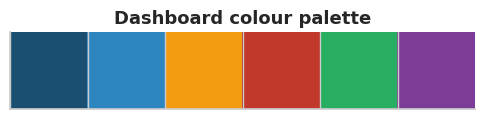

In [5]:
# Custom palette used by every chart (Seaborn and Plotly)
sns.palplot(db.PALETTE)
plt.title("Dashboard colour palette")
plt.show()

## Day 2 – Statistical visualisations (box & violin)

◆ marks the mean; the label above each group is the median.

INFO: Saved visualizations/01_box_order_value_by_product.png


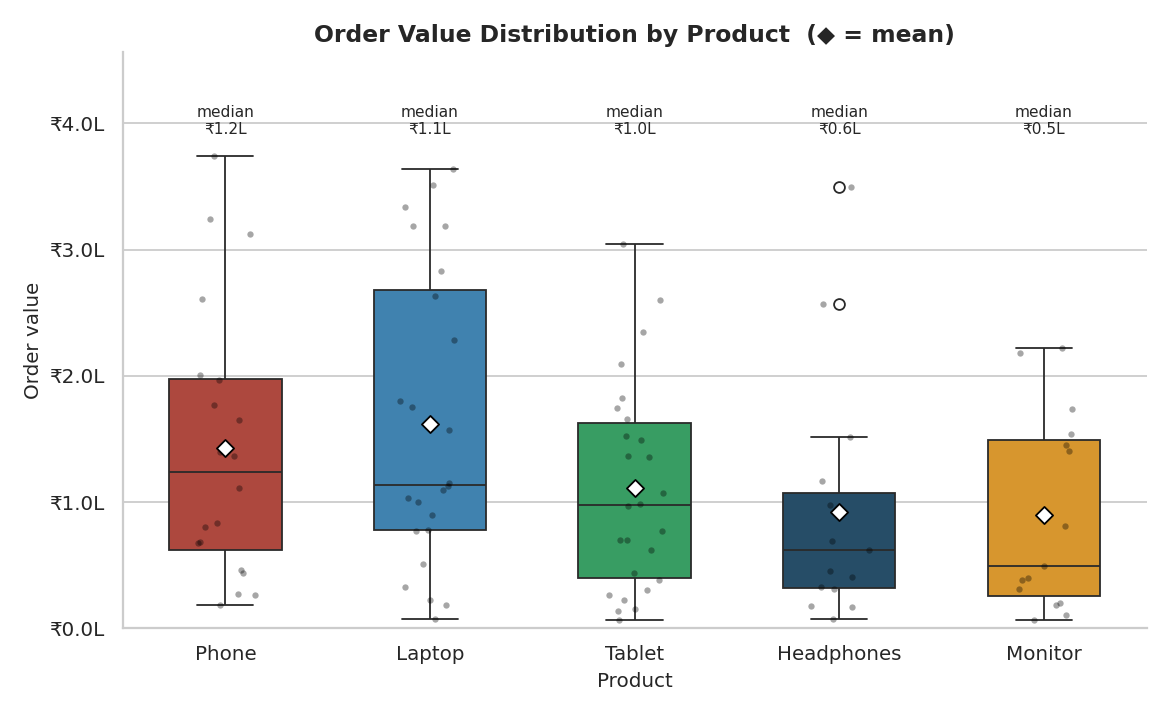

In [6]:
display(Image(db.chart_box_by_product(sales, VIS)))

INFO: Saved visualizations/02_violin_order_value_by_region.png


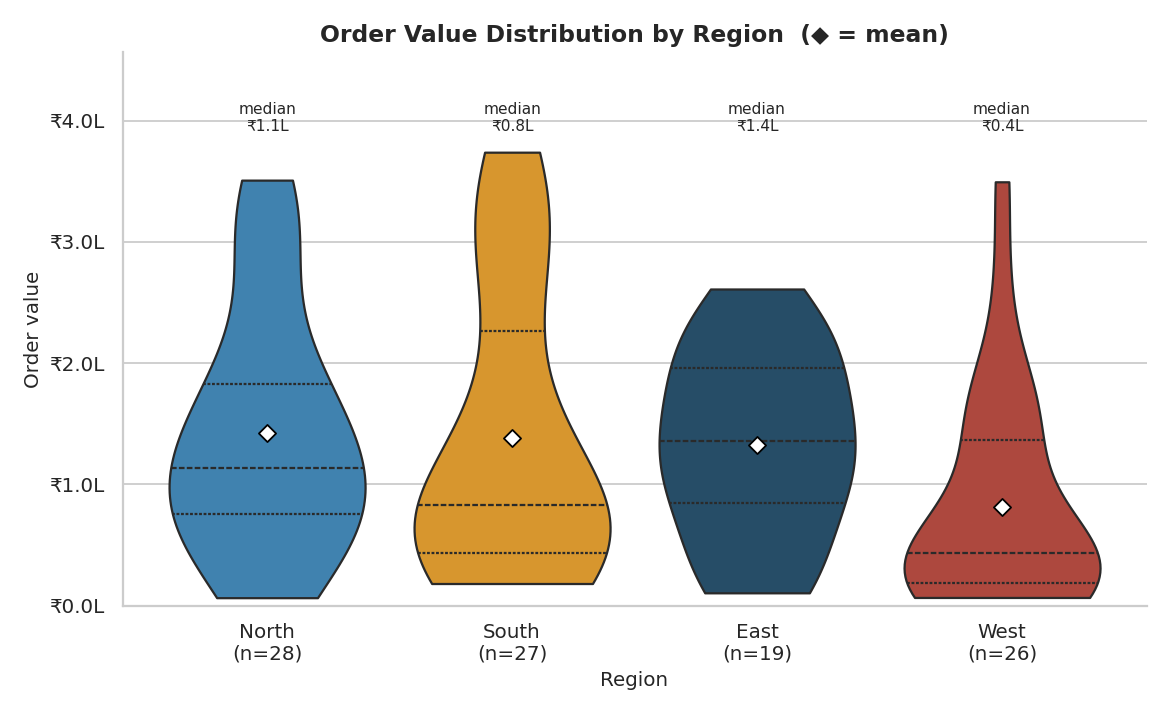

In [7]:
display(Image(db.chart_violin_by_region(sales, VIS)))

**Reading it:** Laptop and Phone have the highest typical order values. West has the lowest median order (~₹0.4L) even though it has many orders.

## Day 3 – Heatmaps & correlation

In [8]:
churn[["Tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "Churn"]].corr().round(2)

,Tenure,MonthlyCharges,TotalCharges,SeniorCitizen,Churn
Tenure,1.00,-0.06,-0.01,-0.04,-0.51
MonthlyCharges,-0.06,1.00,-0.04,-0.11,0.11
TotalCharges,-0.01,-0.04,1.00,0.02,0.00
SeniorCitizen,-0.04,-0.11,0.02,1.00,-0.02
Churn,-0.51,0.11,0.00,-0.02,1.00


INFO: Saved visualizations/03_heatmap_customer_correlation.png


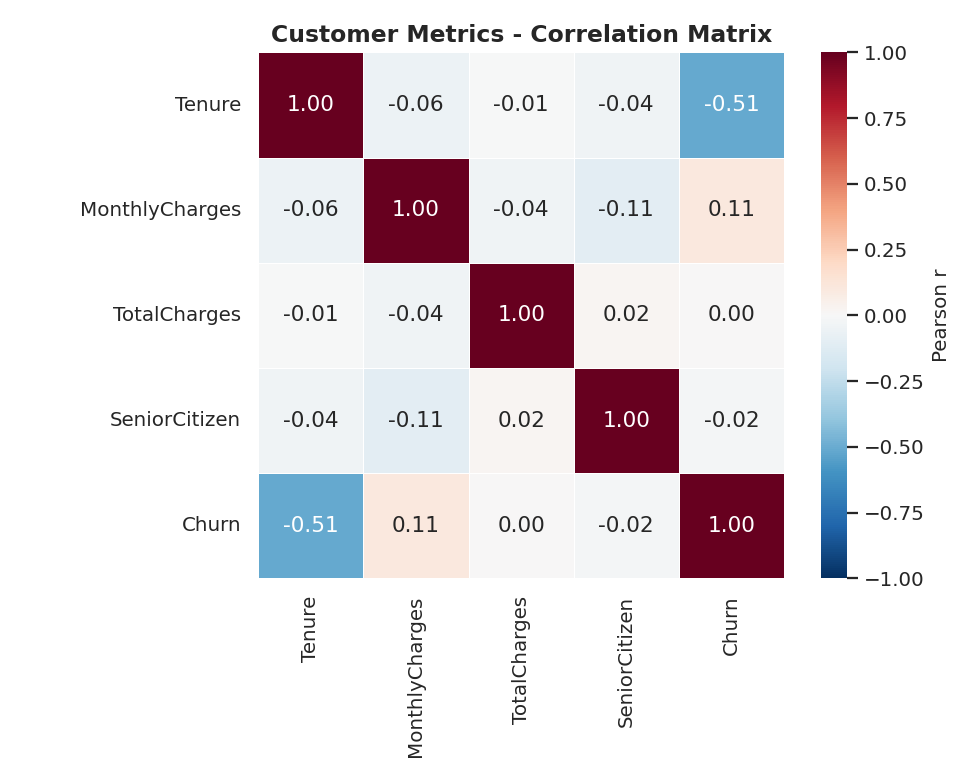

In [9]:
display(Image(db.chart_correlation_heatmap(churn, VIS)))

**Reading it:** tenure is the variable most linked to churn (r ≈ −0.51) – newer customers leave more. TotalCharges is almost unrelated to tenure, which is unusual for billing data, so it is treated with caution.

INFO: Saved visualizations/04_bar_churn_by_contract.png


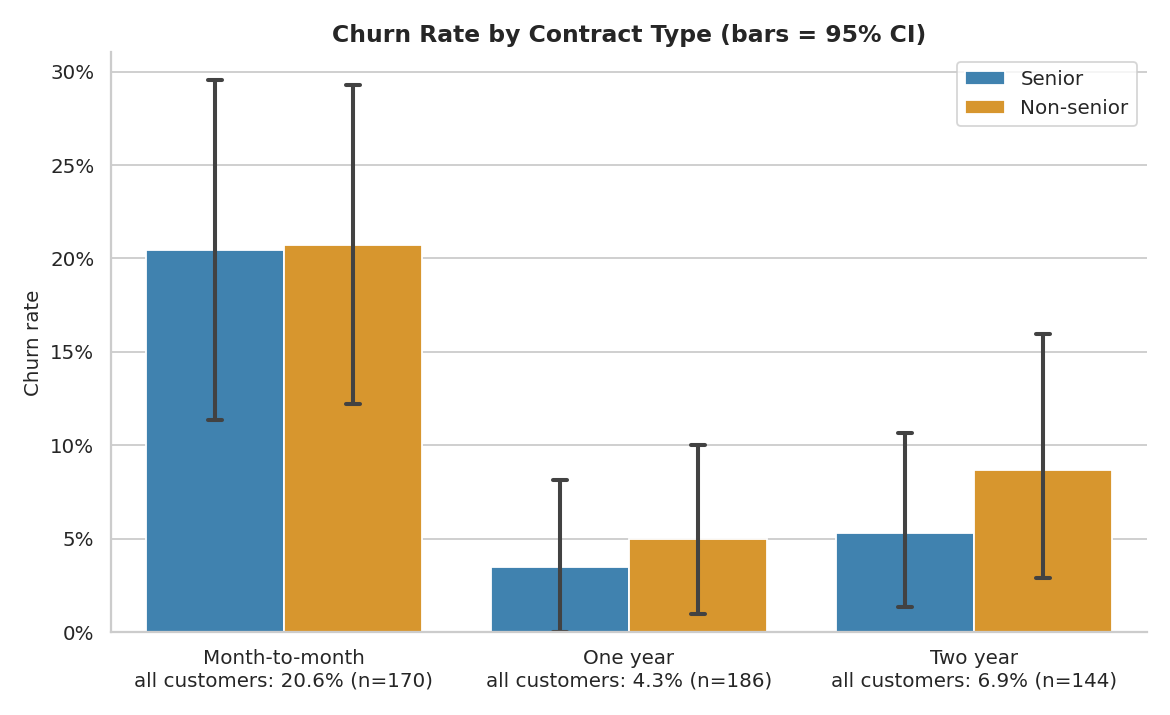

INFO: Saved visualizations/05_hist_tenure_by_churn.png


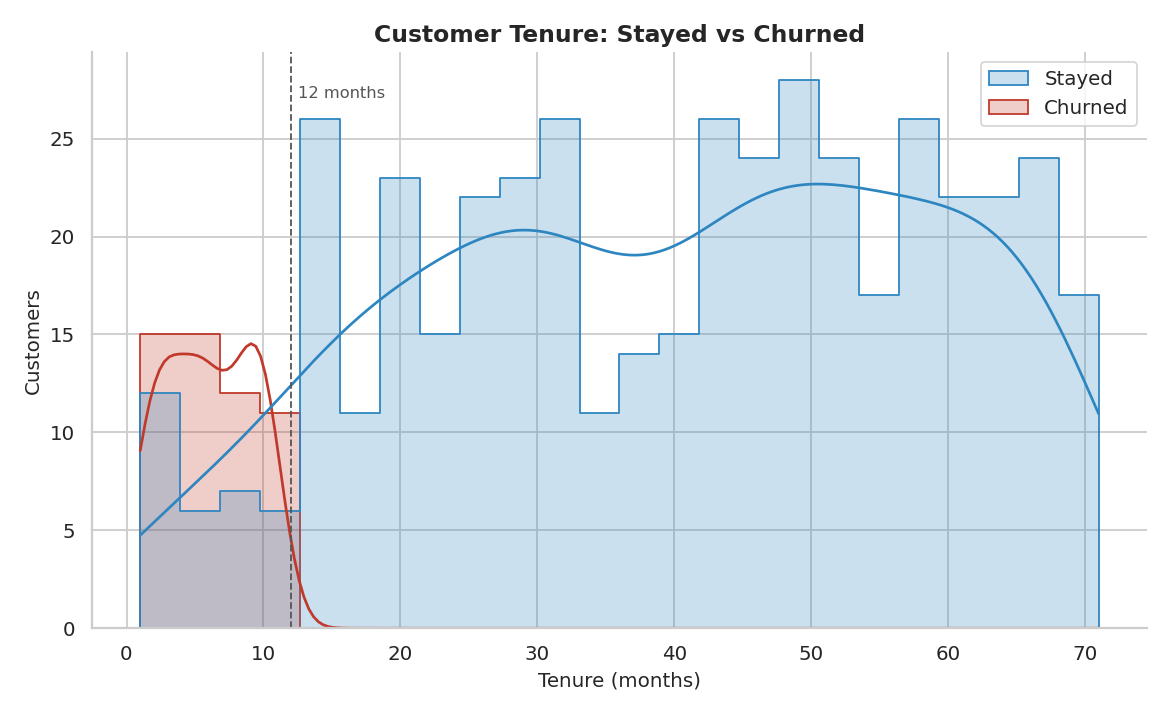

INFO: Saved visualizations/06_scatter_charges_vs_tenure.png


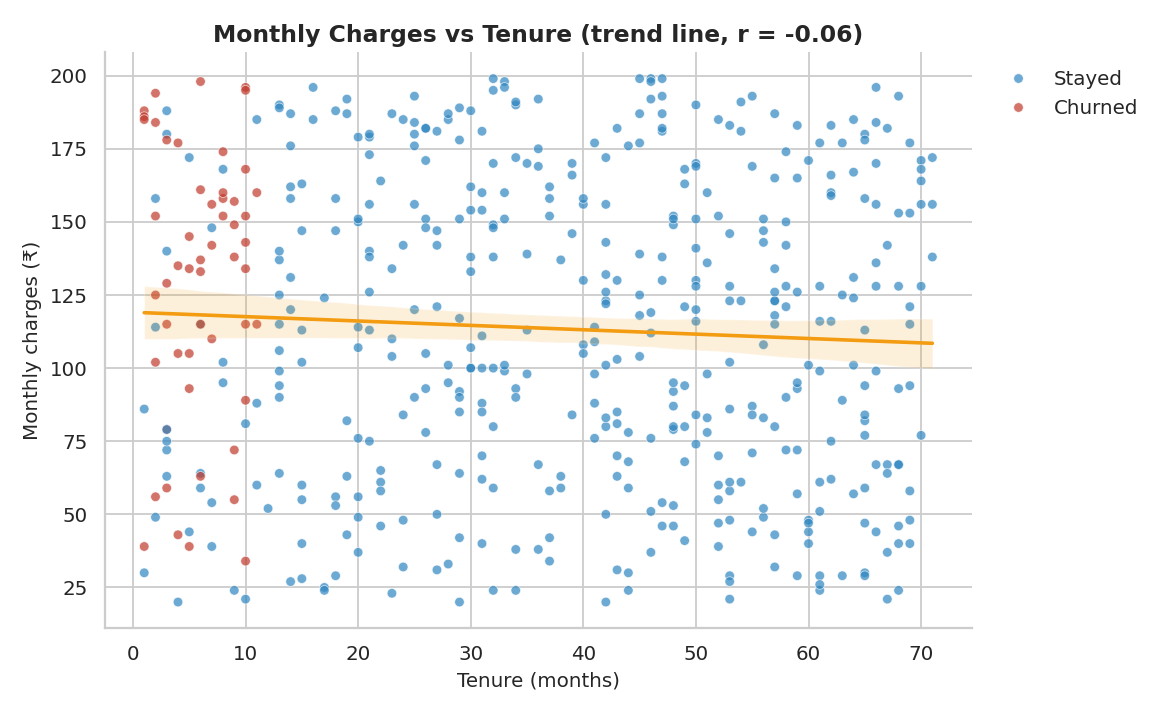

INFO: Saved visualizations/07_line_monthly_revenue_by_product.png


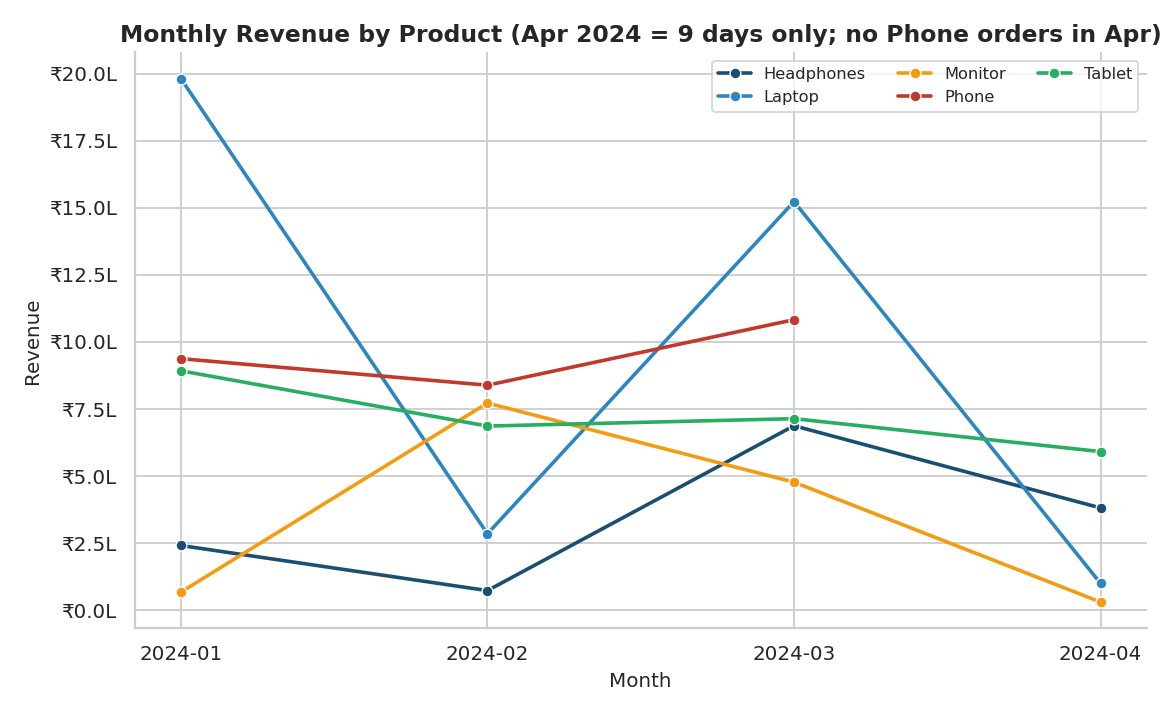

INFO: Saved visualizations/08_pairplot_customers.png


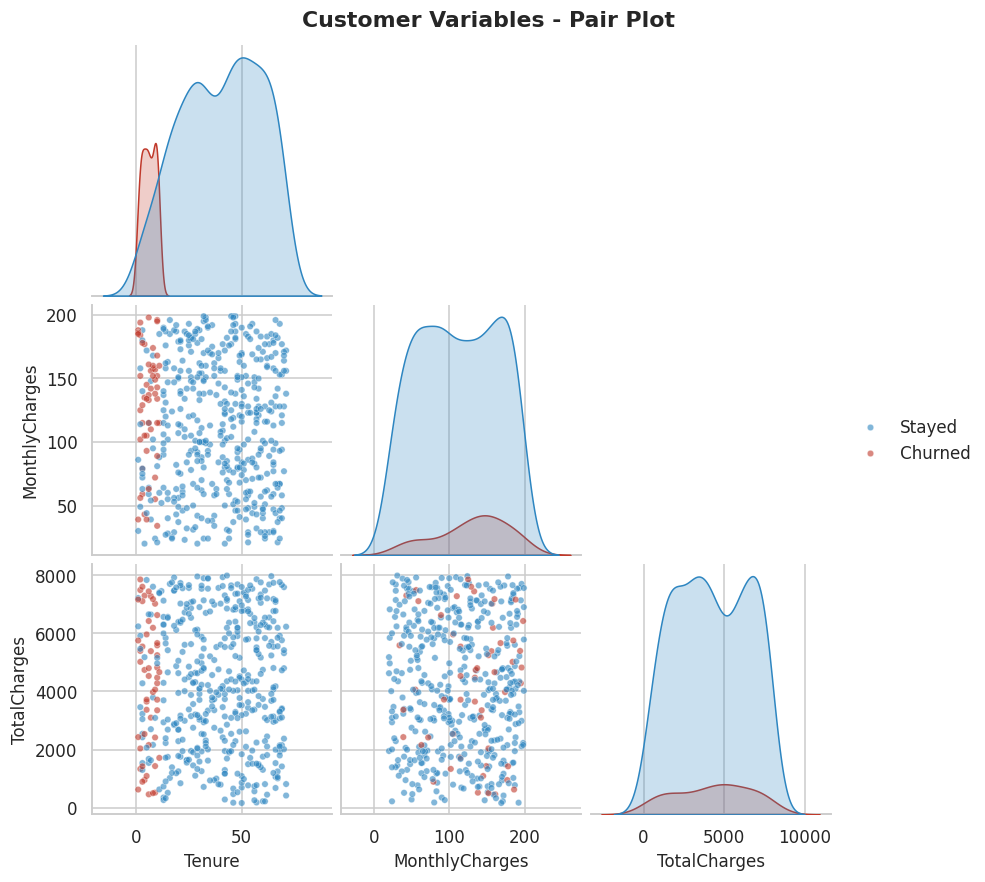

In [10]:
display(Image(db.chart_churn_by_contract(churn, VIS)))
display(Image(db.chart_tenure_histogram(churn, VIS)))
display(Image(db.chart_scatter_regression(churn, VIS)))
display(Image(db.chart_monthly_trend(sales, VIS)))
display(Image(db.chart_pairplot(churn, VIS)))

## Day 4 – 2×2 multi-plot dashboard

INFO: Saved visualizations/00_dashboard_2x2.png


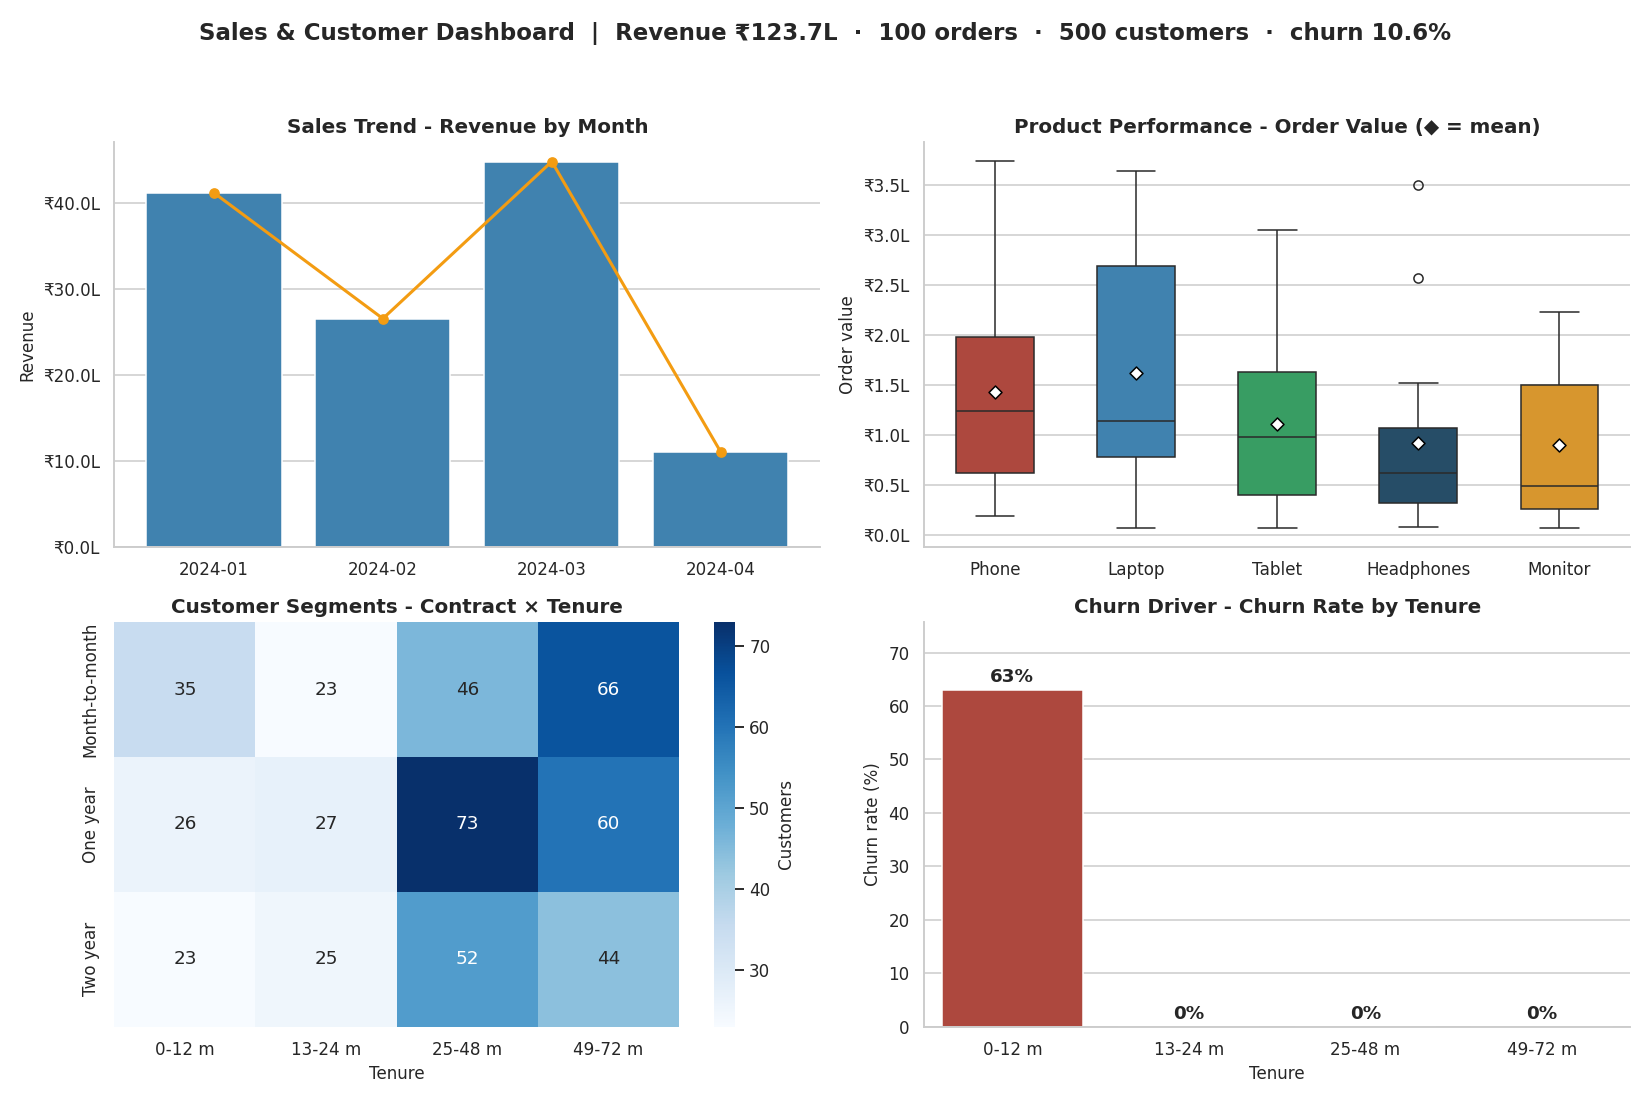

In [11]:
display(Image(db.chart_dashboard_grid(sales, churn, kpis, VIS)))

## Day 5 & 6 – Interactive Plotly charts

Each chart is saved as an HTML file in `visualizations/interactive/`. Open them in a browser to hover, use the dropdowns and press ▶ Play on the animation.

In [12]:
html_files = db.create_interactive_charts(sales, churn, kpis, INTERACTIVE)
for f in html_files:
    print(f.relative_to(ROOT), f"{f.stat().st_size / 1024:.0f} KB")

INFO: Saved visualizations/interactive/interactive_dashboard.html


INFO: Saved visualizations/interactive/sales_trend_dropdown.html


INFO: Saved visualizations/interactive/product_revenue_animation.html


INFO: Saved visualizations/interactive/customer_segments_dropdown.html


visualizations/interactive/interactive_dashboard.html 21 KB
visualizations/interactive/sales_trend_dropdown.html 14 KB
visualizations/interactive/product_revenue_animation.html 11 KB
visualizations/interactive/customer_segments_dropdown.html 55 KB


In [13]:
# Inline preview of the combined dashboard (works in Jupyter; GitHub does not render HTML/JS)
IFrame(src=str((INTERACTIVE / "interactive_dashboard.html").relative_to(ROOT)), width="100%", height=880)

## Day 7 – PDF report & demo GIF

In [14]:
static = db.create_static_charts(sales, churn, kpis, VIS)
pdf = db.write_pdf_report(static, kpis, ROOT / "report" / "dashboard_report.pdf")
gif = db.make_demo_gif(static, ROOT / "dashboard_demo.gif")
print(pdf.relative_to(ROOT), gif.relative_to(ROOT))

INFO: Saved visualizations/00_dashboard_2x2.png


INFO: Saved visualizations/01_box_order_value_by_product.png


INFO: Saved visualizations/02_violin_order_value_by_region.png


INFO: Saved visualizations/03_heatmap_customer_correlation.png


INFO: Saved visualizations/04_bar_churn_by_contract.png


INFO: Saved visualizations/05_hist_tenure_by_churn.png


... (2 outputs left out)

INFO: Saved visualizations/08_pairplot_customers.png


INFO: Saved dashboard_report.pdf


INFO: Saved dashboard_demo.gif (9 frames)


report/dashboard_report.pdf dashboard_demo.gif


## Insights

In [15]:
for i, line in enumerate(db.insights(kpis), 1):
    print(f"{i}. {line}")

1. Laptop is the top product (31.5% of revenue); North is the top region.
2. Overall churn is 10.6% of 500 customers.
3. Month-to-month contracts churn at 20.6% vs 4.3% (one year) and 6.9% (two year).
4. All churn happens in the first year: 63% of customers with ≤12 months tenure churned; no customer above 11 months churned.
5. Tenure has the strongest link to churn (r = -0.51).
6. Churned customers paid more per month on average (₹130 vs ₹112).
7. Data-quality note: TotalCharges is almost unrelated to tenure (r = -0.01), which is unusual - treat TotalCharges with caution.
